1. Построение базовой модели (baseline)

In [255]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [256]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from helper import load_clean_data, get_preprocessor
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay
from sklearn.tree import plot_tree

SEED = 42
np.random.seed(SEED)

In [257]:
df = load_clean_data()
X, y = df.drop(columns=["y"]), df["y"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

tscv = TimeSeriesSplit(n_splits=5)

1.1 Dummy classifier

Для начала попробуем использовать глупый классификатор, который всегда предсказывает только самый частый класс и посмотреть на значение метрик. Это даст нам понимание, от какого нижнего порога метрик нам отталкиваться и с чем сравнивать наши модели.

In [258]:
#собираем препроцессор и модель в один Pipeline
dummy_pipe = Pipeline([
    ("prep", get_preprocessor()),
    ("model", DummyClassifier(strategy="most_frequent")),
])

#оцениваем через кросс-валидацию по времени 
scoring = ["roc_auc", "f1_macro", "precision_macro", "recall_macro", "accuracy"]
cv_res = cross_validate(dummy_pipe, X_train, y_train, cv=tscv, scoring=scoring)

#средние метрики по фолдам
{m: cv_res[f"test_{m}"].mean().round(3) for m in scoring}



/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

{'roc_auc': np.float64(0.5),
 'f1_macro': np.float64(0.481),
 'precision_macro': np.float64(0.463),
 'recall_macro': np.float64(0.5),
 'accuracy': np.float64(0.927)}

Как видим, ROC AUC в этом случае ожидаемо равна 0.5 и f1 = 0.4. Тут важно отметить, что для f1 используется macro усреднение, так как важны оба класса

1.2 Логистическая регрессия

In [259]:
logreg_pipe = Pipeline([
    ("prep", get_preprocessor()),
    ("model", LogisticRegression(random_state=SEED, max_iter=1000, solver="liblinear"))
])

cv_res = cross_validate(logreg_pipe, X_train, y_train, cv=tscv, scoring=scoring)

#средние метрики по фолдам
{m: cv_res[f"test_{m}"].mean().round(3) for m in scoring}


/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

{'roc_auc': np.float64(0.531),
 'f1_macro': np.float64(0.481),
 'precision_macro': np.float64(0.463),
 'recall_macro': np.float64(0.5),
 'accuracy': np.float64(0.927)}

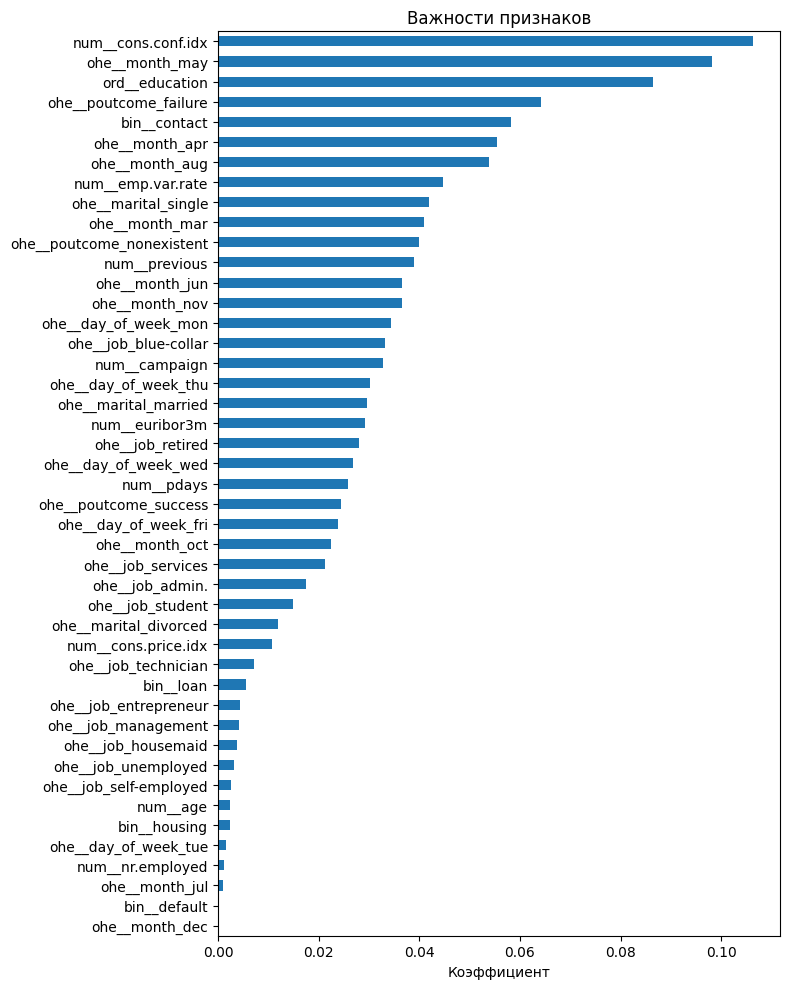

In [260]:
logreg_pipe.fit(X_train, y_train)
#имена признаков после препроцессинга 
feature_names = logreg_pipe.named_steps["prep"].get_feature_names_out()

#коэффициенты модели 
coefs = logreg_pipe.named_steps["model"].coef_[0]

# переводим в Series и сортируем по значению
importance = pd.Series(np.abs(coefs), index=feature_names).sort_values()

#гистограмма 
importance.plot(kind="barh", figsize=(8, 10))
plt.title("Важности признаков")
plt.xlabel("Коэффициент")
plt.tight_layout()

In [261]:
coef_table = pd.DataFrame({
    "feature": feature_names,
    "coef": coefs,
    "abs_coef": np.abs(coefs)
}).sort_values("abs_coef", ascending=False)

coef_table.head(10)

,feature,coef,abs_coef
6,num__cons.conf.idx,-0.106347,0.106347
37,ohe__month_may,-0.098117,0.098117
40,ord__education,0.086351,0.086351
23,ohe__poutcome_failure,-0.064244,0.064244
44,bin__contact,-0.058224,0.058224
31,ohe__month_apr,0.055506,0.055506
32,ohe__month_aug,0.053830,0.053830
4,num__emp.var.rate,-0.044742,0.044742
22,ohe__marital_single,0.041979,0.041979
36,ohe__month_mar,0.040868,0.040868


В случае логрега на первом месте оказался индекс доверия потребителей, в целом это логично так как в матрице корреляций корреляция с таргетам равна 0.50 

1.3 Дерево решений

In [262]:
decision_tree_pipe = Pipeline([
    ("prep", get_preprocessor()),
    ("model", DecisionTreeClassifier(random_state=SEED, max_depth=4))
])

cv_res = cross_validate(logreg_pipe, X_train, y_train, cv=tscv, scoring=scoring)

#средние метрики по фолдам
{m: cv_res[f"test_{m}"].mean().round(3) for m in scoring}


/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

{'roc_auc': np.float64(0.531),
 'f1_macro': np.float64(0.481),
 'precision_macro': np.float64(0.463),
 'recall_macro': np.float64(0.5),
 'accuracy': np.float64(0.927)}

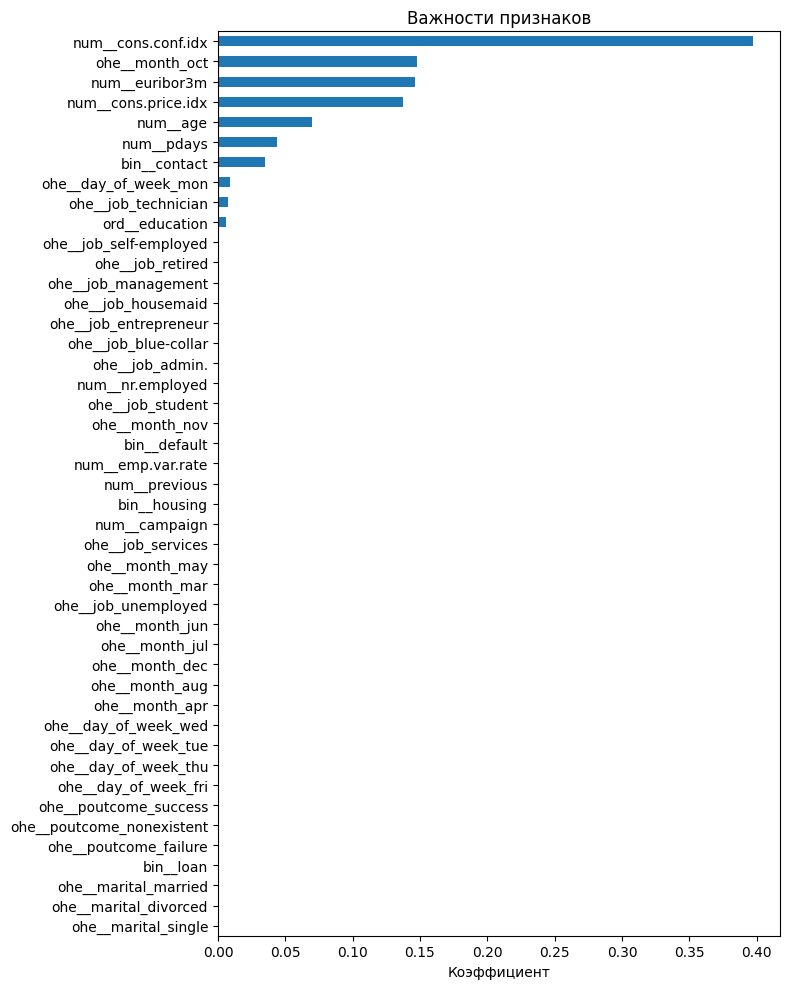

In [263]:
decision_tree_pipe.fit(X_train, y_train)
#имена признаков после препроцессинга 
feature_names = decision_tree_pipe.named_steps["prep"].get_feature_names_out()

# переводим в Series и сортируем по значению
importance = pd.Series(decision_tree_pipe.named_steps["model"].feature_importances_, index=feature_names).sort_values()

#гистограмма 
importance.plot(kind="barh", figsize=(8, 10))
plt.title("Важности признаков")
plt.xlabel("Коэффициент")
plt.tight_layout()

In [264]:
importance_table = pd.DataFrame({
    "feature": feature_names,
    "importance": decision_tree_pipe.named_steps["model"].feature_importances_,
}).sort_values("importance", ascending=False)

importance_table.head(10)

,feature,importance
6,num__cons.conf.idx,0.397471
39,ohe__month_oct,0.147856
7,num__euribor3m,0.146388
5,num__cons.price.idx,0.137542
0,num__age,0.069874
2,num__pdays,0.043824
44,bin__contact,0.034807
27,ohe__day_of_week_mon,0.008962
18,ohe__job_technician,0.007260
40,ord__education,0.006017


Как и в логреге самый важный признак - cons.conf.idx. Визуализируем дерево

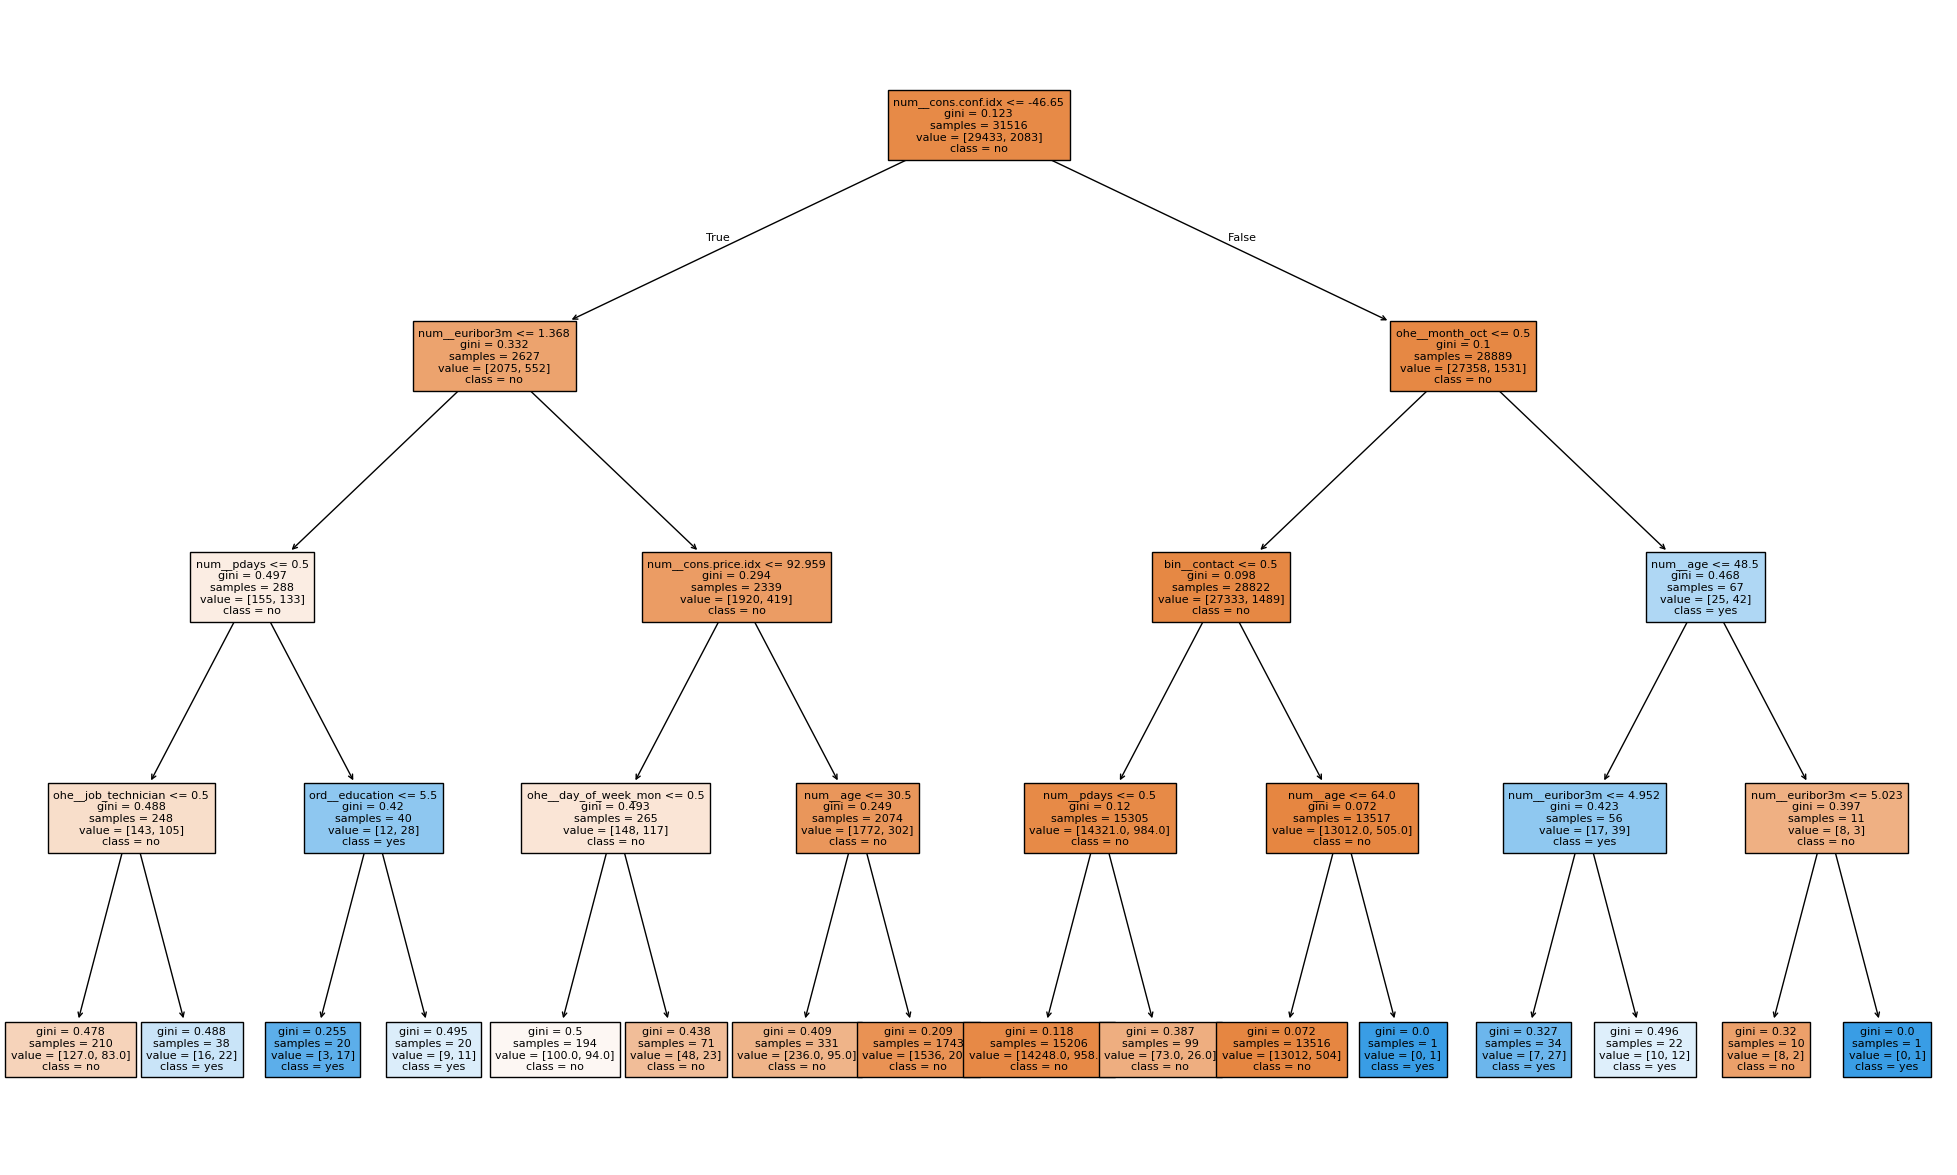

In [265]:
feature_names = decision_tree_pipe.named_steps["prep"].get_feature_names_out()

plt.figure(figsize=(25, 15))
plot_tree(
    decision_tree_pipe.named_steps["model"],
    feature_names=feature_names,
    class_names=["no", "yes"],
    filled=True,        # цветом кодирует класс
    max_depth=4,        
    fontsize=8
)
plt.show()

1.4 Случайный лес 

In [266]:
random_forest_pipe = Pipeline([
    ("prep", get_preprocessor()),
    ("model", RandomForestClassifier(random_state=SEED))
])

cv_res = cross_validate(random_forest_pipe, X_train, y_train, cv=tscv, scoring=scoring)

#средние метрики по фолдам
{m: cv_res[f"test_{m}"].mean().round(3) for m in scoring}


/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


{'roc_auc': np.float64(0.499),
 'f1_macro': np.float64(0.481),
 'precision_macro': np.float64(0.48),
 'recall_macro': np.float64(0.5),
 'accuracy': np.float64(0.926)}

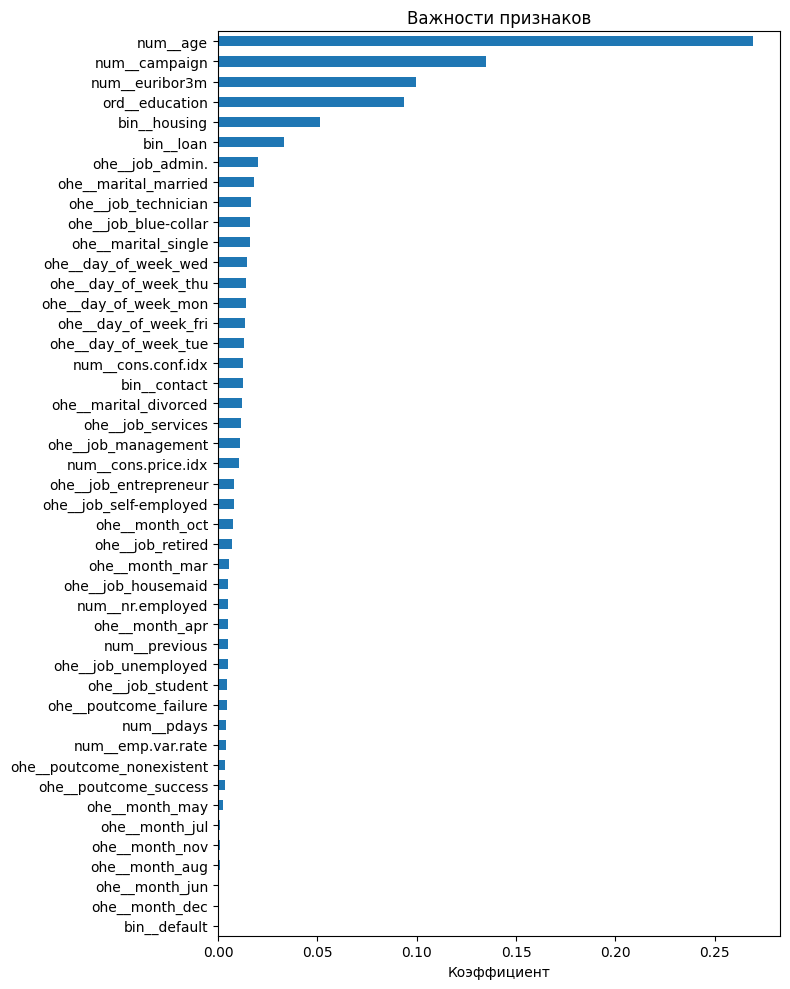

In [267]:
random_forest_pipe.fit(X_train, y_train)
#имена признаков после препроцессинга 
feature_names = random_forest_pipe.named_steps["prep"].get_feature_names_out()

# переводим в Series и сортируем по значению
importance = pd.Series(random_forest_pipe.named_steps["model"].feature_importances_, index=feature_names).sort_values()

#гистограмма 
importance.plot(kind="barh", figsize=(8, 10))
plt.title("Важности признаков")
plt.xlabel("Коэффициент")
plt.tight_layout()

In [268]:
importance_table = pd.DataFrame({
    "feature": feature_names,
    "importance": random_forest_pipe.named_steps["model"].feature_importances_,
}).sort_values("importance", ascending=False)

importance_table.head(10)

,feature,importance
0,num__age,0.269339
1,num__campaign,0.134674
7,num__euribor3m,0.099579
40,ord__education,0.093765
42,bin__housing,0.051155
43,bin__loan,0.033332
9,ohe__job_admin.,0.019909
21,ohe__marital_married,0.018154
18,ohe__job_technician,0.016632
10,ohe__job_blue-collar,0.015994


Тут картина отличается от других моделей, здесь на первом месте признак возраста клиентов. При этом cons.conf.idx не входит даже в топ 10 

1.5 Градиентный бустинг 

In [269]:
lgbm_pipe = Pipeline([
    ("prep", get_preprocessor()),
    ("model", LGBMClassifier(random_state=SEED))
])

cv_res = cross_validate(lgbm_pipe, X_train, y_train, cv=tscv, scoring=scoring)

#средние метрики по фолдам
{m: cv_res[f"test_{m}"].mean().round(3) for m in scoring}


/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/utils/v

{'roc_auc': np.float64(0.503),
 'f1_macro': np.float64(0.481),
 'precision_macro': np.float64(0.463),
 'recall_macro': np.float64(0.5),
 'accuracy': np.float64(0.926)}

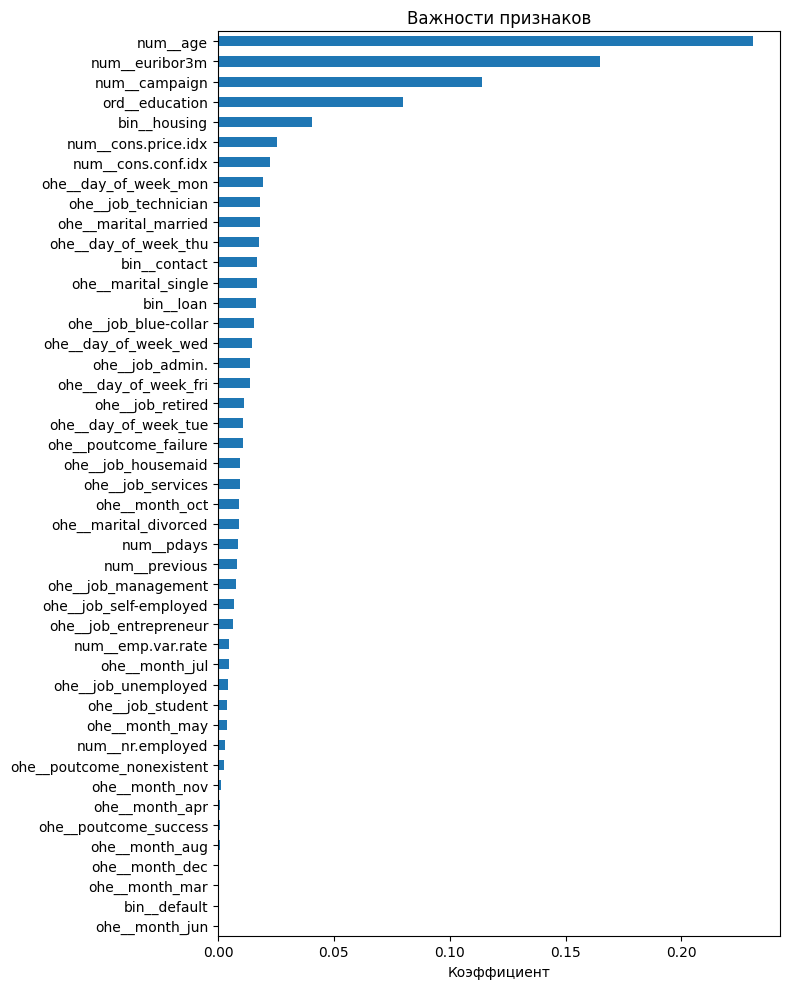

In [270]:
lgbm_pipe.fit(X_train, y_train)
#имена признаков после препроцессинга 
feature_names = lgbm_pipe.named_steps["prep"].get_feature_names_out()

# переводим в Series и сортируем по значению
importance = pd.Series((lgbm_pipe.named_steps["model"].feature_importances_ / lgbm_pipe.named_steps["model"].feature_importances_.sum()), 
                       index=feature_names).sort_values() #тут мы делим, чтобы на графике на оси Х были коэффициенты, а не абсолютные числа

#гистограмма 
importance.plot(kind="barh", figsize=(8, 10))
plt.title("Важности признаков")
plt.xlabel("Коэффициент")
plt.tight_layout()

In [271]:
importance_table = pd.DataFrame({
    "feature": feature_names,
    "importance": lgbm_pipe.named_steps["model"].feature_importances_ / lgbm_pipe.named_steps["model"].feature_importances_.sum(),
}).sort_values("importance", ascending=False)

importance_table.head(10)

,feature,importance
0,num__age,0.231000
7,num__euribor3m,0.164667
1,num__campaign,0.114000
40,ord__education,0.080000
42,bin__housing,0.040667
5,num__cons.price.idx,0.025667
6,num__cons.conf.idx,0.022667
27,ohe__day_of_week_mon,0.019333
18,ohe__job_technician,0.018000
21,ohe__marital_married,0.018000


Здесь на первом месте признак возраста клиентов 

1.6 Финальное сравнение метрик

/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

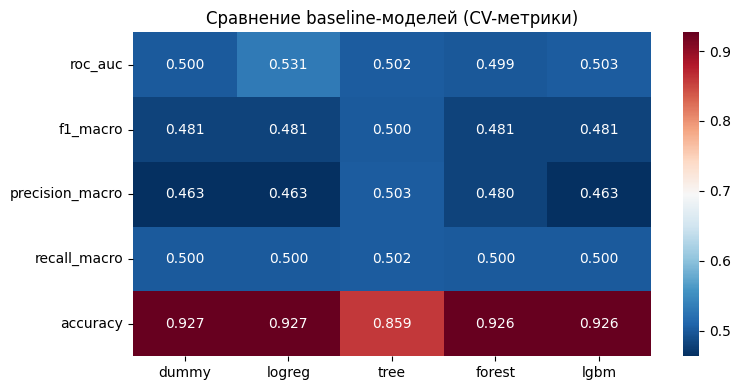

In [273]:
models = {
      "dummy":  DummyClassifier(strategy="most_frequent"),
      "logreg": LogisticRegression(random_state=SEED, max_iter=1000, solver="liblinear"),
      "tree":   DecisionTreeClassifier(random_state=SEED),
      "forest": RandomForestClassifier(random_state=SEED),
      "lgbm":   LGBMClassifier(random_state=SEED, verbose=-1),
  }
results = {}
for name, model in models.items():
    pipe = Pipeline([("prep", get_preprocessor()), ("model", model)])
    cv_res = cross_validate(pipe, X_train, y_train, cv=tscv, scoring=scoring)
    results[name] = {m: cv_res[f"test_{m}"].mean() for m in scoring}

results_df = pd.DataFrame(results)


plt.figure(figsize=(8, 4))
sns.heatmap(results_df, annot=True, fmt=".3f", cmap="RdBu_r")
plt.title("Сравнение baseline-моделей (CV-метрики)")
plt.tight_layout()

ВЫВОД:

Все модели показали плохие метрики: ROC-AUC около 0.50, то есть они предсказывают почти как случайное угадывание и не лучше тупого классификатора. Сначала это выглядит как провал, но причина важная, и она определяет всю дальнейшую работу.

Дело не в коде и не в плохих данных. Я проверил (потом удалил, чтоб не захламлять ноутбук): если разбить данные случайно (с перемешиванием), та же модель LightGBM даёт ROC-AUC 0.80 — значит данные прекрасно обучаемы. Проблема именно во временном разбиении, которое мы обязаны использовать по условию задачи.

Почему так получилось. Самые сильные признаки в датасете — макроэкономические (euribor3m, nr.employed, emp.var.rate и др.). Они привязаны ко времени и постоянно меняются из-за кризиса 2008–2010: например, ставка euribor3m в раннем периоде около 4.8, а в позднем падает до 0.6–1.5. Модель обучается на ранних данных и запоминает правила для значений около 4.8, а в валидационной выборке приходят значения, которых она никогда не видела. Деревья и бустинг не умеют работать за пределами виденного диапазона, поэтому их правила перестают действовать, и предсказания становятся случайными. Случайное разбиение эту проблему скрывает, потому что подмешивает будущие периоды в обучение — но это, по сути, подглядывание в будущее, которое нельзя допустить.

Вторая проблема — дисбаланс и его дрейф во времени: доля положительного класса растёт с 4% в начале до 14% в конце (внутри X_train). Из-за этого модели на сыром датасете склонны предсказывать только мажоритарный класс, и редкий класс «да» почти не ловится.

Что из этого следует для improvements. Нужно: ослабить влияние нестационарных макропризнаков (они фактически кодируют время и не переносятся на будущее), чтобы модель больше опиралась на стабильные признаки клиента; применить балансировку классов (SMOTE или class_weight), чтобы модель начала распознавать редкий класс; проверить каждое изменение через ту же временную кросс-валидацию и сравнить прирост метрик с baseline.